# Le Secret du Titan: which features find the matching installment?

Results from `compare_features.py` (re-run it after new features are computed; this notebook only reads its output).

**Main measure: progression.** For every installment we take its best match and ask whether the best matches
follow the order of the novel: the Spearman correlation between where an installment really is and where its
best match is. 1 = every installment found in the right order, 0 = random.

Also shown: **top-1** (share of installments whose best match is the right one) and, for the noise test,
**separation** (how far the right match stands out from all other candidates).

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

features = Path("secret_du_titan/features")
comparison = pd.DataFrame(json.loads((features / "comparison.json").read_text()))
robustness = pd.DataFrame(json.loads((features / "robustness.json").read_text()))

# fixed colour + marker + line style per feature (identity never rests on colour alone)
STYLE = {
    "MFW":            dict(color="#2a78d6", marker="o", linestyle="-"),
    "passim":         dict(color="#eb6834", marker="s", linestyle="--"),
    "GTE histlux":    dict(color="#1baf7a", marker="^", linestyle="-."),
    "GTE OCR-robust": dict(color="#eda100", marker="D", linestyle=":"),
}
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({"axes.edgecolor": GRID, "axes.labelcolor": INK, "xtick.color": MUTED,
                     "ytick.color": MUTED, "axes.spines.top": False, "axes.spines.right": False,
                     "font.size": 11})

## 1. The text pairs

| pair | what it tests | right answer |
|---|---|---|
| fr vs fr_en_fr | French vs its round trip (FR→EN→FR, Google) | known: same installment |
| fr vs fr_en | French vs its English translation | known: same installment |
| de vs fr_de | real German (1891) vs Google's German of the French | approximate: same relative position, ±1 installment |
| de vs fr | real German vs the French directly (the real task) | approximate: same relative position, ±1 installment |

MFW and passim only work within one language, so they are missing for the cross-language pairs.

In [2]:
table = comparison.pivot_table(index="pair", columns="feature", values="progression")
table = table.reindex(["fr vs fr_en_fr", "fr vs fr_en", "de vs fr_de", "de vs fr"]).dropna(how="all")
print("progression (Spearman, 1 = best matches follow the novel)")
table.round(2)

progression (Spearman, 1 = best matches follow the novel)


feature,MFW,passim
pair,,
fr vs fr_en_fr,1.00,1.00
de vs fr_de,0.72,0.92


In [3]:
top1 = comparison.pivot_table(index="pair", columns="feature", values="top1")
top1 = top1.reindex(table.index)
chance = comparison.groupby("pair")["chance_top1"].first().reindex(table.index)
print("top-1 (share of installments whose best match is right); chance level in the last column")
top1.assign(chance=chance).round(2)

top-1 (share of installments whose best match is right); chance level in the last column


feature,MFW,passim,chance
pair,,,
fr vs fr_en_fr,1.00,1.00,0.01
de vs fr_de,0.37,0.53,0.03


## 2. How fast does each feature break under OCR noise?

We take the round-trip French (clean: Google fixed the OCR while translating), add simulated OCR noise
(`corrupt.py`: confused letters such as e/c, n/u, rn/m; lost accents; dropped letters; stray punctuation;
split and glued words) and match each corrupted installment back to the original French.

The shaded band is where Impresso's real OCR of this novel lies (its OCR-quality score 0.60–0.96,
translated to our noise scale with the same score).

In [4]:
levels = robustness.groupby("noise")["ocrqa"].first()
real = [json.loads(l)["ocrqa"] for l in open("secret_du_titan/fr.jsonl")
        if json.loads(l).get("ocr_source") == "impresso"]
# noise level that gives the same OCR-quality score (ocrqa falls as noise rises)
to_noise = lambda q: float(np.interp(-q, -levels.values, levels.index.values))
band = (to_noise(max(real)) * 100, to_noise(min(real)) * 100)
median = to_noise(float(np.median(real))) * 100
print(f"Impresso's real French OCR ≈ {band[0]:.1f}–{band[1]:.1f}% simulated noise (median {median:.1f}%)")
print(levels.rename("mean OCR-quality score").to_frame().T.round(2))

Impresso's real French OCR ≈ 0.3–9.3% simulated noise (median 1.4%)
noise                   0.000  0.010  0.020  0.030  0.050  0.075  0.100  \
mean OCR-quality score   0.98   0.91   0.85    0.8   0.72   0.64   0.58   

noise                   0.150  0.200  0.300  
mean OCR-quality score   0.49   0.43   0.36  


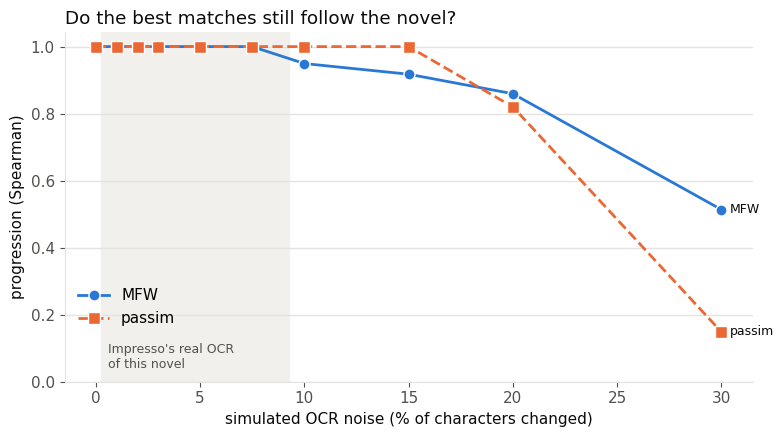

In [5]:
def decay_plot(measure, ylabel, title, relative=False):
    fig, ax = plt.subplots(figsize=(8, 4.5))
    ax.axvspan(*band, color="#f1f0ec", zorder=0)
    ax.text(band[0] + 0.3, 0.04, "Impresso's real OCR\nof this novel", color=MUTED, fontsize=9,
            transform=ax.get_xaxis_transform())
    for feature, rows in robustness.groupby("feature"):
        rows = rows.sort_values("noise")
        y = rows[measure] / rows[measure].iloc[0] if relative else rows[measure]
        ax.plot(rows["noise"] * 100, y, label=feature, linewidth=2, markersize=8,
                markeredgecolor="white", **STYLE[feature])
        ax.annotate(feature, (rows["noise"].iloc[-1] * 100, y.iloc[-1]), xytext=(6, 0),
                    textcoords="offset points", va="center", fontsize=9, color=INK)
    ax.set_xlabel("simulated OCR noise (% of characters changed)")
    ax.set_ylabel(ylabel)
    ax.set_title(title, loc="left", color=INK)
    ax.set_ylim(bottom=min(0, ax.get_ylim()[0]))
    ax.grid(axis="y", color=GRID, linewidth=1)
    ax.legend(frameon=False, loc="lower left", bbox_to_anchor=(0, 0.12))
    fig.tight_layout()
    return fig

decay_plot("progression", "progression (Spearman)",
           "Do the best matches still follow the novel?");

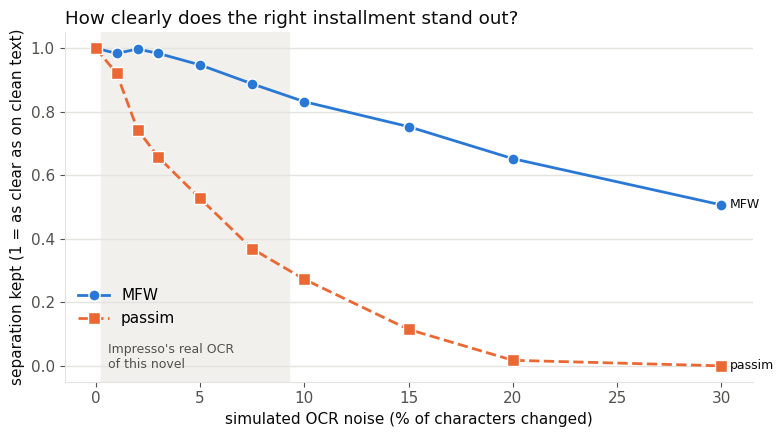

In [6]:
decay_plot("separation", "separation kept (1 = as clear as on clean text)",
           "How clearly does the right installment stand out?", relative=True);

In [7]:
print("the same numbers as a table (progression)")
robustness.pivot_table(index="noise", columns="feature", values="progression").round(2)

the same numbers as a table (progression)


feature,MFW,passim
noise,,
0.000,1.00,1.00
0.010,1.00,1.00
0.020,1.00,1.00
0.030,1.00,1.00
0.050,1.00,1.00
0.075,1.00,1.00
0.100,0.95,1.00
0.150,0.92,1.00
0.200,0.86,0.82
